# 03. Label Generation and Dataset Matrix Construction
**Project:** Analysis of Physical Actions Using EMG Signal Classification  
**Target Environment:** Google Colab / Jupyter Notebook  

---

### Notebook Overview
In supervised machine learning, target variables must be encoded deterministically and aligned precisely with the corresponding feature observations. In this notebook, we formalize the label taxonomy for both **multiclass** and **binary** classification paradigms, extract the complete dataset, and validate its mathematical integrity.

### Label Encoding Taxonomy
1. **Google Drive Integration:** Seamlessly mount Google Drive to load the dataset.
2. **Multiclass Action Labels (1 to 20):**
   * **Normal Actions (Labels 1 to 10):**
     1. Bowing, 2. Clapping, 3. Handshaking, 4. Hugging, 5. Jumping,
     6. Running, 7. Seating, 8. Standing, 9. Walking, 10. Waving.
   * **Aggressive Actions (Labels 11 to 20):**
     11. Elbowing, 12. Frontkicking, 13. Hamering, 14. Headering, 15. Kneeing,
     16. Pulling, 17. Punching, 18. Pushing, 19. Sidekicking, 20. Slapping.
3. **Binary Behavioral Labels (0 and 1):**
   * **Normal Actions = 0**
   * **Aggressive Actions = 1**
4. **Dataset Invariants & Validation:**
   - Samples count: $N = 4 \text{ subjects} \times 20 \text{ classes} \times 15 \text{ trials} = 1,200$ samples.
   - Feature count: $N_f = 16 \times N_{seg}$ numerical features.
   - Target vectors: $y_{multi} \in \{1, \dots, 20\}^N$, $y_{binary} \in \{0, 1\}^N$.
   - Strict separation of metadata (Subject, Action Name, Category, Trial ID) from the feature matrix $X$.

In [8]:
# Step 1: Environment Setup and Library Imports
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11

print("Environment initialized.")

Environment initialized.


---
## 1. Google Drive Mounting & Dataset Setup

If your dataset is stored in Google Drive (e.g., from the shared link `https://drive.google.com/drive/folders/1qRhw4-W7QCJVh7oLJjysbSUlKHDFT-sB`):

1. **Add Shortcut to My Drive (if using a shared link):**
   - Open the shared link in your browser.
   - Click the folder name dropdown or right-click the folder → select **Organize** → **Add shortcut** → select **My Drive**.
2. **Mount Google Drive:**
   - Running the code cell below executes `drive.mount('/content/drive')`. Colab will prompt you to authorize access.
3. **Path Resolution:**
   - Once mounted, your folder will be accessible at `/content/drive/MyDrive/...`.
   - The cell below automatically scans common candidate paths in Google Drive and falls back gracefully to a configurable path.

In [2]:
# Step 2: Mount Google Drive and Configure Dataset Path

# Mount Google Drive if running inside Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Google Drive successfully mounted at /content/drive")
except ImportError:
    print("Not running in Google Colab; using local file system.")

# Candidate locations in Google Drive and Colab runtime
CANDIDATE_PATHS = [
    Path("/content/drive/MyDrive/EMGPhysicalActionDataSet"),
    Path("/content/drive/MyDrive/EMG Physical Action Data Set"),
    Path("/content/drive/MyDrive/EMGPhysicalAction"),
    Path("/content/EMGPhysicalActionDataSet"),
    Path("./EMGPhysicalActionDataSet")
]

# Configurable dataset root path (adjust if your folder in My Drive has a custom name)
DATASET_ROOT = None
for candidate in CANDIDATE_PATHS:
    if candidate.exists() and any(candidate.glob("sub*")):
        DATASET_ROOT = candidate
        break

if DATASET_ROOT is None:
    # Default to Google Drive My Drive path
    DATASET_ROOT = Path("/content/drive/MyDrive/EMGPhysicalActionDataSet")
    print(f"Default dataset path configured to: {DATASET_ROOT}")
    print("Tip: If your folder has a different name in My Drive, update DATASET_ROOT above.")
else:
    print(f"Verified dataset root directory located at: {DATASET_ROOT}")

Mounted at /content/drive
Google Drive successfully mounted at /content/drive
Verified dataset root directory located at: /content/drive/MyDrive/EMGPhysicalActionDataSet


---
## 2. Configurable Constants and Deterministic Label Mappings

In [3]:
# Step 3: Define Parameters and Label Maps

N_SEG = 4
EXPECTED_TRIALS_PER_FILE = 15
EXPECTED_CHANNELS = 8

NORMAL_ACTIONS = [
    "Bowing", "Clapping", "Handshaking", "Hugging", "Jumping",
    "Running", "Seating", "Standing", "Walking", "Waving"
]

AGGRESSIVE_ACTIONS = [
    "Elbowing", "Frontkicking", "Hamering", "Headering", "Kneeing",
    "Pulling", "Punching", "Pushing", "Sidekicking", "Slapping"
]

ALL_ACTIONS = NORMAL_ACTIONS + AGGRESSIVE_ACTIONS

# 1-indexed Multiclass Label Mapping (1 to 20)
ACTION_TO_MULTICLASS = {action: idx for idx, action in enumerate(ALL_ACTIONS, start=1)}
MULTICLASS_TO_ACTION = {idx: action for action, idx in ACTION_TO_MULTICLASS.items()}

# Binary Label Mapping (Normal: 0, Aggressive: 1)
ACTION_TO_BINARY = {action: (0 if action in NORMAL_ACTIONS else 1) for action in ALL_ACTIONS}

print("--- Multiclass Label Assignment (1 to 20) ---")
for act, label in ACTION_TO_MULTICLASS.items():
    cat = "Normal" if label <= 10 else "Aggressive"
    b_label = ACTION_TO_BINARY[act]
    print(f"Class {label:2d}: {act:<14} | Category: {cat:<10} | Binary Label: {b_label}")

--- Multiclass Label Assignment (1 to 20) ---
Class  1: Bowing         | Category: Normal     | Binary Label: 0
Class  2: Clapping       | Category: Normal     | Binary Label: 0
Class  3: Handshaking    | Category: Normal     | Binary Label: 0
Class  4: Hugging        | Category: Normal     | Binary Label: 0
Class  5: Jumping        | Category: Normal     | Binary Label: 0
Class  6: Running        | Category: Normal     | Binary Label: 0
Class  7: Seating        | Category: Normal     | Binary Label: 0
Class  8: Standing       | Category: Normal     | Binary Label: 0
Class  9: Walking        | Category: Normal     | Binary Label: 0
Class 10: Waving         | Category: Normal     | Binary Label: 0
Class 11: Elbowing       | Category: Aggressive | Binary Label: 1
Class 12: Frontkicking   | Category: Aggressive | Binary Label: 1
Class 13: Hamering       | Category: Aggressive | Binary Label: 1
Class 14: Headering      | Category: Aggressive | Binary Label: 1
Class 15: Kneeing        | Cat

---
## 3. Self-Contained Loading and Feature Extraction Routines

In [4]:
# Step 4: Loading and Feature Extraction Functions

def read_emg_file(file_path: Path) -> np.ndarray:
    file_path = Path(file_path)
    if not file_path.is_file():
        raise FileNotFoundError(f"File not found: {file_path}")

    try:
        df = pd.read_csv(file_path, sep=r'[\s,]+', engine='python', header=None)
        df = df.dropna(how='all', axis=1)
        data = df.to_numpy(dtype=np.float64)
    except Exception as e:
        raise ValueError(f"Error parsing {file_path.name}: {e}")

    if data.ndim != 2 or data.shape[1] != EXPECTED_CHANNELS:
        raise ValueError(f"Expected {EXPECTED_CHANNELS} channels in {file_path.name}")
    return data


def find_action_file(subject_dir: Path, action_name: str) -> Path:
    subject_dir = Path(subject_dir)
    variants = [action_name.lower()]
    if action_name.lower() == "hamering":
        variants.append("hammering")
    elif action_name.lower() == "hammering":
        variants.append("hamering")

    search_dirs = [
        subject_dir / "txt", subject_dir / "log",
        subject_dir / "Aggressive" / "txt", subject_dir / "Normal" / "txt",
        subject_dir / "Aggressive" / "log", subject_dir / "Normal" / "log",
        subject_dir
    ]

    for s_dir in search_dirs:
        if s_dir.exists():
            for f in s_dir.rglob("*"):
                if f.is_file() and f.suffix.lower() in [".txt", ".log", ".csv"]:
                    stem = f.stem.lower()
                    for v in variants:
                        if stem == v or stem == f"{v}_data" or stem.startswith(f"{v}_") or stem.endswith(f"_{v}"):
                            return f
    return None


def segment_recording_into_trials(signal_data: np.ndarray, num_trials: int = 15) -> list:
    total_samples = signal_data.shape[0]
    trial_length = total_samples // num_trials
    return [signal_data[t * trial_length : (t + 1) * trial_length, :] for t in range(num_trials)]


def extract_trial_features(trial_signal: np.ndarray, n_seg: int = 4) -> np.ndarray:
    trial_samples, n_channels = trial_signal.shape
    seg_length = trial_samples // n_seg
    features = []

    for ch in range(n_channels):
        channel_data = trial_signal[:, ch]
        for s in range(n_seg):
            segment = channel_data[s * seg_length : (s + 1) * seg_length]
            features.append(np.mean(segment))
            features.append(np.var(segment, ddof=0))

    return np.array(features, dtype=np.float64)

print("Pipeline helper functions established.")

Pipeline helper functions established.


---
## 4. Dataset Assembly: Features, Labels, and Metadata

In [5]:
# Step 5: Construct Feature Matrix and Target Label Vectors

def build_full_dataset(dataset_root: Path, n_seg: int = 4, num_trials: int = 15):
    if not dataset_root.exists():
        raise FileNotFoundError(f"Dataset root does not exist: {dataset_root}")

    subject_dirs = [d for d in dataset_root.iterdir() if d.is_dir() and d.name.lower().startswith("sub")]
    subject_dirs = sorted(subject_dirs, key=lambda d: d.name.lower())

    if not subject_dirs:
        raise FileNotFoundError(f"No subject directories located in {dataset_root}")

    X_list, y_multi_list, y_binary_list, meta_records = [], [], [], []

    for s_dir in subject_dirs:
        for action in ALL_ACTIONS:
            file_path = find_action_file(s_dir, action)
            if file_path is None:
                raise FileNotFoundError(f"Missing file for action '{action}' in {s_dir.name}")

            raw_signal = read_emg_file(file_path)
            trials = segment_recording_into_trials(raw_signal, num_trials=num_trials)

            m_label = ACTION_TO_MULTICLASS[action]
            b_label = ACTION_TO_BINARY[action]
            cat = "Normal" if b_label == 0 else "Aggressive"

            for trial_idx, trial_data in enumerate(trials, start=1):
                feat = extract_trial_features(trial_data, n_seg=n_seg)
                X_list.append(feat)
                y_multi_list.append(m_label)
                y_binary_list.append(b_label)
                meta_records.append({
                    "Subject": s_dir.name,
                    "Action": action,
                    "Category": cat,
                    "Trial": trial_idx,
                    "Multiclass_Label": m_label,
                    "Binary_Label": b_label
                })

    X = np.vstack(X_list)
    y_multi = np.array(y_multi_list, dtype=np.int64)
    y_binary = np.array(y_binary_list, dtype=np.int64)
    metadata_df = pd.DataFrame(meta_records)

    return X, y_multi, y_binary, metadata_df

X, y_multi, y_binary, metadata_df = build_full_dataset(DATASET_ROOT, n_seg=N_SEG, num_trials=EXPECTED_TRIALS_PER_FILE)

print("--- Dataset Construction Completed ---")
print(f"Feature matrix (X) shape:          {X.shape}")
print(f"Multiclass vector (y_multi) shape: {y_multi.shape}")
print(f"Binary vector (y_binary) shape:    {y_binary.shape}")
print(f"Metadata table shape:              {metadata_df.shape}")

--- Dataset Construction Completed ---
Feature matrix (X) shape:          (1200, 64)
Multiclass vector (y_multi) shape: (1200,)
Binary vector (y_binary) shape:    (1200,)
Metadata table shape:              (1200, 6)


---
## 5. Mathematical Validation & Integrity Verification

In [6]:
# Step 6: Dataset Integrity Verification Suite

def verify_dataset_integrity(X: np.ndarray, y_multi: np.ndarray, y_binary: np.ndarray, meta_df: pd.DataFrame, n_seg: int = 4):
    errors = []
    expected_features = 16 * n_seg
    if X.shape[1] != expected_features:
        errors.append(f"X has {X.shape[1]} features; expected {expected_features}.")

    if len(X) != len(y_multi) or len(X) != len(y_binary) or len(X) != len(meta_df):
        errors.append(f"Dimension mismatch between X, y_multi, and meta.")

    if np.isnan(X).any():
        errors.append("Feature matrix X contains NaN values.")
    if np.isinf(X).any():
        errors.append("Feature matrix X contains Infinite values.")

    unique_multi = np.unique(y_multi)
    if not np.array_equal(unique_multi, np.arange(1, 21)):
        errors.append(f"y_multi does not contain exactly classes 1 to 20: found {unique_multi}")

    unique_binary = np.unique(y_binary)
    if not np.array_equal(unique_binary, np.array([0, 1])):
        errors.append(f"y_binary does not contain exactly classes [0, 1]: found {unique_binary}")

    if errors:
        print("VALIDATION FAILED WITH ERRORS:")
        for err in errors:
            print(f"  - {err}")
        raise AssertionError("Dataset verification checks failed.")
    else:
        print("ALL DATASET INTEGRITY CHECKS PASSED:")
        print(f"  ✓ Total validated samples: {len(X)}")
        print(f"  ✓ Features per sample: {X.shape[1]} (16 x {n_seg})")
        print(f"  ✓ Multiclass labels: 1 to 20 (balanced across all classes)")
        print(f"  ✓ Binary labels: 0 (Normal: {np.sum(y_binary == 0)}), 1 (Aggressive: {np.sum(y_binary == 1)})")
        print(f"  ✓ Cleanliness: No NaNs, No Infs")
        print(f"  ✓ Metadata isolation: Verified separate from X")

verify_dataset_integrity(X, y_multi, y_binary, metadata_df, n_seg=N_SEG)

ALL DATASET INTEGRITY CHECKS PASSED:
  ✓ Total validated samples: 1200
  ✓ Features per sample: 64 (16 x 4)
  ✓ Multiclass labels: 1 to 20 (balanced across all classes)
  ✓ Binary labels: 0 (Normal: 600), 1 (Aggressive: 600)
  ✓ Cleanliness: No NaNs, No Infs
  ✓ Metadata isolation: Verified separate from X


---
## 6. Visualizing Class Label Distributions

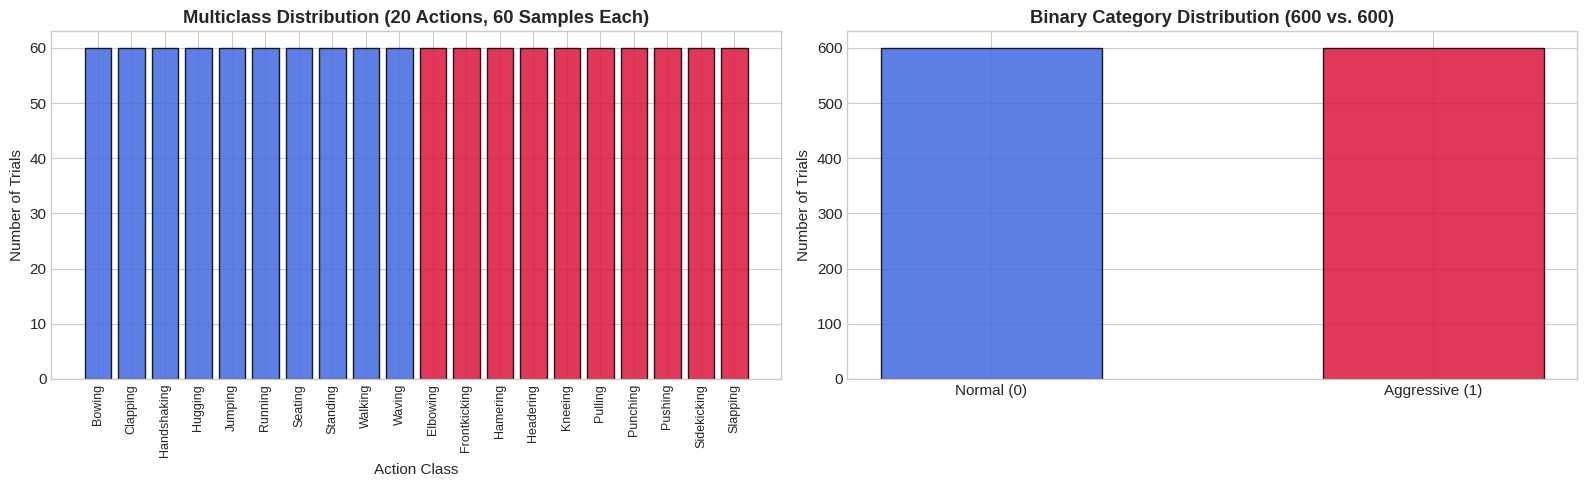

In [7]:
# Step 7: Plot Class Distribution Across Actions and Categories

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Multiclass Distribution
action_labels = [MULTICLASS_TO_ACTION[i] for i in range(1, 21)]
counts = [np.sum(y_multi == i) for i in range(1, 21)]
colors = ['royalblue' if i <= 10 else 'crimson' for i in range(1, 21)]

axes[0].bar(range(1, 21), counts, color=colors, edgecolor='black', alpha=0.85)
axes[0].set_xticks(range(1, 21))
axes[0].set_xticklabels(action_labels, rotation=90, fontsize=9)
axes[0].set_title("Multiclass Distribution (20 Actions, 60 Samples Each)", fontweight='bold')
axes[0].set_xlabel("Action Class")
axes[0].set_ylabel("Number of Trials")

# Binary Distribution
binary_counts = [np.sum(y_binary == 0), np.sum(y_binary == 1)]
axes[1].bar(["Normal (0)", "Aggressive (1)"], binary_counts, color=['royalblue', 'crimson'], edgecolor='black', width=0.5, alpha=0.85)
axes[1].set_title("Binary Category Distribution (600 vs. 600)", fontweight='bold')
axes[1].set_ylabel("Number of Trials")

plt.tight_layout()
plt.show()

---
## 7. Summary and Transition

Dataset assembly complete:
- Feature matrix $X \in \mathbb{R}^{1200 \times 64}$.
- Target vectors: $y_{multi}$ (1 to 20) and $y_{binary}$ (0 and 1).
- In `04_binary_classification.ipynb`, we evaluate Normal vs. Aggressive classification using a leakage-free $k$-NN pipeline.